<a href="https://colab.research.google.com/github/DivyaMeenaSundaram/Forensics/blob/main/Copy_move_forgery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install pillow matplotlib

Saving Red Hatchback and Blue Traffic Cone.png to Red Hatchback and Blue Traffic Cone.png
========== IMAGE FORENSICS ==========

1. IMAGE INFORMATION
Filename: Red Hatchback and Blue Traffic Cone.png
Dimensions: (1536, 1024)
Image format: PNG

2. METADATA ANALYSIS
No EXIF metadata found.

3. ERROR LEVEL ANALYSIS


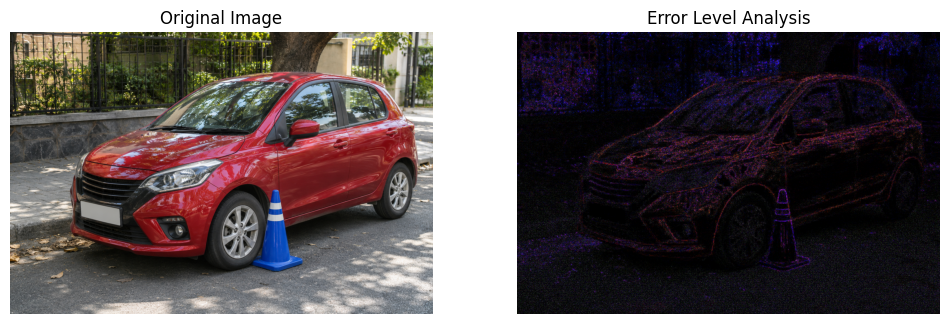


ANALYSIS COMPLETED
Inspect bright or inconsistent regions manually.


In [5]:

from PIL import Image, ImageChops, ImageEnhance
from google.colab import files
import matplotlib.pyplot as plt
import io
import os

# Upload image
uploaded = files.upload()
filename = list(uploaded.keys())[0]

img = Image.open(filename).convert("RGB")

print("========== IMAGE FORENSICS ==========")

# 1. IMAGE INFORMATION
print("\n1. IMAGE INFORMATION")
print("Filename:", filename)
print("Dimensions:", img.size)
print("Image format:", Image.open(filename).format)

# 2. METADATA ANALYSIS
print("\n2. METADATA ANALYSIS")

original = Image.open(filename)
exif = original.getexif()

if exif:
    for tag, value in exif.items():
        print(tag, ":", value)
else:
    print("No EXIF metadata found.")

# 3. ERROR LEVEL ANALYSIS (ELA)
print("\n3. ERROR LEVEL ANALYSIS")

buffer = io.BytesIO()
img.save(buffer, format="JPEG", quality=90)
buffer.seek(0)

compressed = Image.open(buffer).convert("RGB")

difference = ImageChops.difference(img, compressed)
ela = ImageEnhance.Contrast(difference).enhance(10)

# Display original and ELA
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(ela)
plt.title("Error Level Analysis")
plt.axis("off")

plt.show()

print("\nANALYSIS COMPLETED")
print("Inspect bright or inconsistent regions manually.")


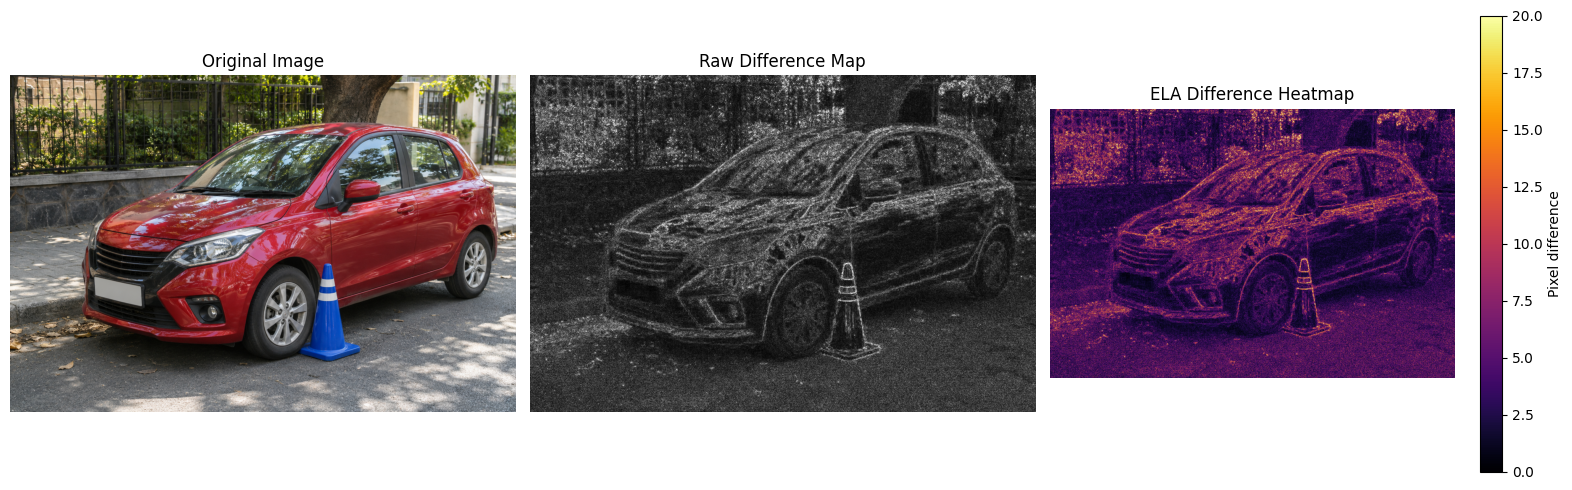

Maximum pixel difference: 62
Mean pixel difference: 4.287


In [6]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageChops
import io

# Original image
img = Image.open(filename).convert("RGB")

# Recompress at JPEG quality 90
buffer = io.BytesIO()
img.save(buffer, format="JPEG", quality=90)
buffer.seek(0)

compressed = Image.open(buffer).convert("RGB")

# Calculate absolute pixel differences
diff = np.abs(
    np.array(img, dtype=np.int16) -
    np.array(compressed, dtype=np.int16)
)

# Convert RGB differences into one intensity map
ela_map = np.max(diff, axis=2)

# Display three outputs
fig, ax = plt.subplots(1, 3, figsize=(16, 5))

ax[0].imshow(img)
ax[0].set_title("Original Image")

ax[1].imshow(ela_map, cmap="gray", vmin=0, vmax=20)
ax[1].set_title("Raw Difference Map")

heat = ax[2].imshow(ela_map, cmap="inferno", vmin=0, vmax=20)
ax[2].set_title("ELA Difference Heatmap")
plt.colorbar(heat, ax=ax[2], label="Pixel difference")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

print("Maximum pixel difference:", ela_map.max())
print("Mean pixel difference:", round(ela_map.mean(), 3))


In [1]:
!pip -q install opencv-python-headless scikit-learn matplotlib

Saving original.jpg to original.jpg
Image dimensions: 1080 x 1920


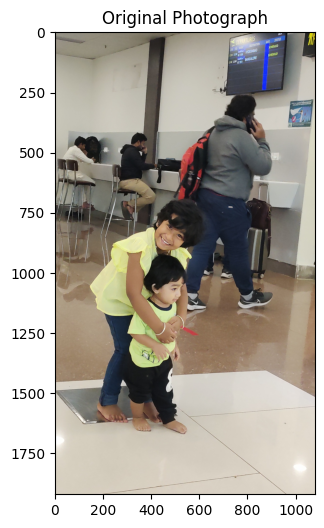

In [2]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files

# Upload original photograph
uploaded = files.upload()
filename = list(uploaded.keys())[0]

img = cv2.imread(filename)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

h, w = img.shape[:2]

print("Image dimensions:", w, "x", h)

plt.figure(figsize=(10, 6))
plt.imshow(img)
plt.title("Original Photograph")
plt.axis("on")
plt.show()


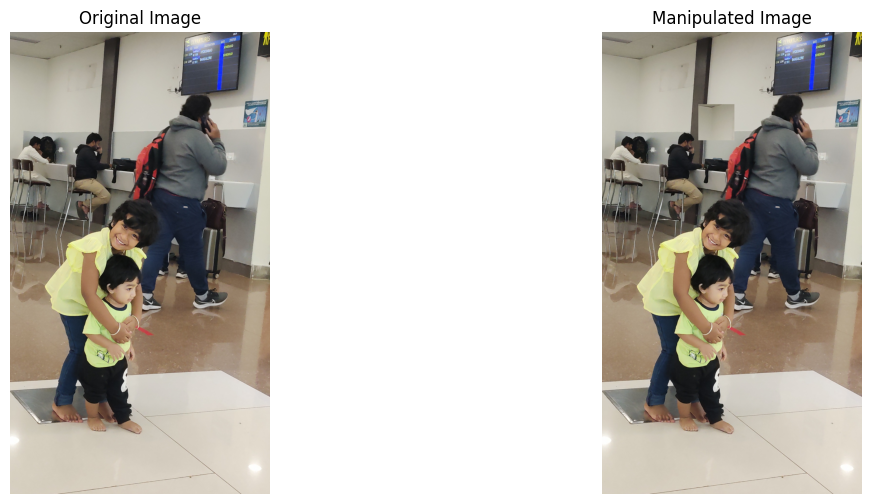

In [3]:

# Select the region to copy
x1, y1 = 100, 100
x2, y2 = 250, 250

# Destination location
paste_x, paste_y = 400, 300

# Create manipulated image
manipulated = img.copy()

# Extract selected region
patch = img[y1:y2, x1:x2]

ph, pw = patch.shape[:2]

# Check destination boundaries
if paste_x + pw > w or paste_y + ph > h:
    raise ValueError("Destination is outside image boundaries.")

# Paste the copied region
manipulated[paste_y:paste_y+ph,
            paste_x:paste_x+pw] = patch

# Save manipulated photograph
cv2.imwrite(
    "manipulated_image.jpg",
    cv2.cvtColor(manipulated, cv2.COLOR_RGB2BGR),
    [cv2.IMWRITE_JPEG_QUALITY, 95]
)

# Compare
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(manipulated)
plt.title("Manipulated Image")
plt.axis("off")

plt.show()


In [4]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN

# Read manipulated image
image = cv2.imread("manipulated_image.jpg")
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Step 1: Extract SIFT features
sift = cv2.SIFT_create(nfeatures=4000)

keypoints, descriptors = sift.detectAndCompute(
    gray, None
)

print("Detected keypoints:", len(keypoints))

if descriptors is None or len(keypoints) < 5:
    raise ValueError("Insufficient image features.")

# Step 2: Match features within the same image
matcher = cv2.BFMatcher(cv2.NORM_L2)

pairs = matcher.knnMatch(
    descriptors, descriptors, k=3
)

matches = []

for pair in pairs:
    # Remove self-matches
    candidates = [
        m for m in pair
        if m.queryIdx != m.trainIdx
    ]

    if len(candidates) < 2:
        continue

    candidates.sort(key=lambda m: m.distance)

    m, n = candidates[0], candidates[1]

    # Lowe's ratio test
    if m.distance < 0.75 * n.distance:

        p1 = np.array(
            keypoints[m.queryIdx].pt
        )

        p2 = np.array(
            keypoints[m.trainIdx].pt
        )

        # Exclude nearby matching features
        if np.linalg.norm(p1 - p2) > 40:
            matches.append(m)

print("Potential distant feature matches:", len(matches))

# Step 3: Analyse displacement vectors
vectors = []

for m in matches:

    p1 = np.array(keypoints[m.queryIdx].pt)
    p2 = np.array(keypoints[m.trainIdx].pt)

    vectors.append(p2 - p1)

if len(vectors) < 4:
    print("Insufficient matching features for detection.")

else:

    vectors = np.array(vectors)

    # Group matches having similar movement
    clustering = DBSCAN(
        eps=12,
        min_samples=4
    ).fit(vectors)

    labels = clustering.labels_

    valid = labels[labels != -1]

    if len(valid) == 0:

        print("No consistent duplicated region detected.")

    else:

        # Identify strongest displacement cluster
        cluster_id, count = max(
            ((i, np.sum(labels == i))
             for i in set(labels) if i != -1),
            key=lambda x: x[1]
        )

        selected = [
            m for m, label in zip(matches, labels)
            if label == cluster_id
        ]

        print("Matching features in strongest cluster:", count)

        # Step 4: Draw matched features
        result = cv2.drawMatches(
            image, keypoints,
            image, keypoints,
            selected[:40],
            None,
            flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
        )

        plt.figure(figsize=(16, 7))
        plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
        plt.title("Copy-Move Forgery: Feature Matches")
        plt.axis("off")
        plt.show()

        # Step 5: Highlight matched regions
        marked = image.copy()

        points1 = np.array([
            keypoints[m.queryIdx].pt
            for m in selected
        ])

        points2 = np.array([
            keypoints[m.trainIdx].pt
            for m in selected
        ])

        for points in [points1, points2]:

            x_min, y_min = points.min(axis=0).astype(int)
            x_max, y_max = points.max(axis=0).astype(int)

            cv2.rectangle(
                marked,
                (x_min-15, y_min-15),
                (x_max+15, y_max+15),
                (0, 255, 0),
                3
            )

        plt.figure(figsize=(12, 7))
        plt.imshow(cv2.cvtColor(marked, cv2.COLOR_BGR2RGB))
        plt.title("Potential Copy-Move Regions")
        plt.axis("off")
        plt.show()


Detected keypoints: 3258
Potential distant feature matches: 97
No consistent duplicated region detected.


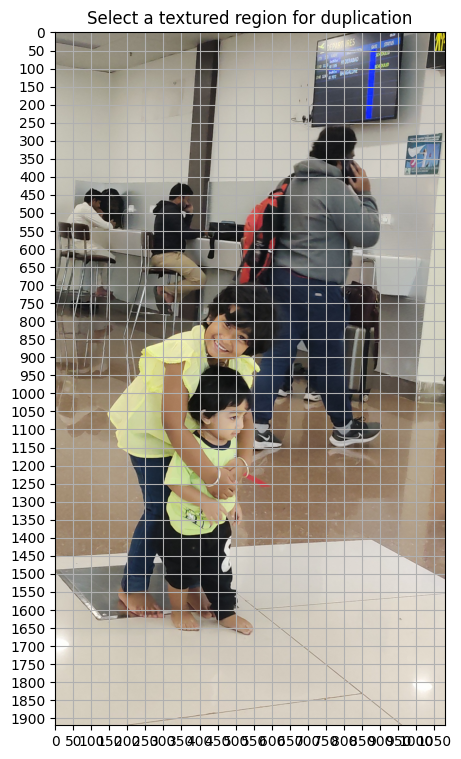

Width: 1080 Height: 1920


In [5]:

import matplotlib.pyplot as plt

h, w = img.shape[:2]

plt.figure(figsize=(10, 9))
plt.imshow(img)
plt.xticks(range(0, w, 50))
plt.yticks(range(0, h, 50))
plt.grid()
plt.title("Select a textured region for duplication")
plt.show()

print("Width:", w, "Height:", h)


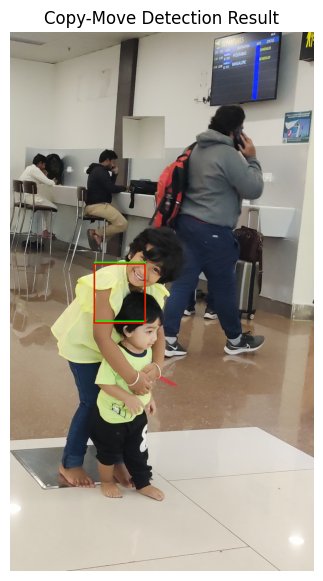

Matching confidence: 0.9339
Suspected duplicate location: (299, 826)


In [8]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use the original and manipulated images
original = img.copy()
test_image = manipulated.copy()

# SOURCE REGION: change these coordinates
x1, y1 = 300, 820
x2, y2 = 480, 1030

# Extract the original region
template = original[y1:y2, x1:x2]

# Convert to grayscale
gray_test = cv2.cvtColor(
    test_image, cv2.COLOR_RGB2GRAY
)

gray_template = cv2.cvtColor(
    template, cv2.COLOR_RGB2GRAY
)

# Ensure the template contains enough texture
if np.std(gray_template) < 5:
    raise ValueError(
        "Selected region is too plain. Choose a textured region."
    )

# Search for the copied region
result = cv2.matchTemplate(
    gray_test,
    gray_template,
    cv2.TM_CCOEFF_NORMED
)

# Ignore the original location
result[
    max(0, y1-5):min(result.shape[0], y1+6),
    max(0, x1-5):min(result.shape[1], x1+6)
] = -1

# Find best matching location
_, confidence, _, location = cv2.minMaxLoc(result)

px, py = location
ph, pw = gray_template.shape

# Display detection result
output = test_image.copy()

# Original source region: green
cv2.rectangle(
    output,
    (x1, y1), (x2, y2),
    (0, 255, 0), 3
)

# Suspected duplicate: red
cv2.rectangle(
    output,
    (px, py), (px+pw, py+ph),
    (255, 0, 0), 3
)

plt.figure(figsize=(12, 7))
plt.imshow(output)
plt.title("Copy-Move Detection Result")
plt.axis("off")
plt.show()

print("Matching confidence:", round(confidence, 4))
print("Suspected duplicate location:", location)


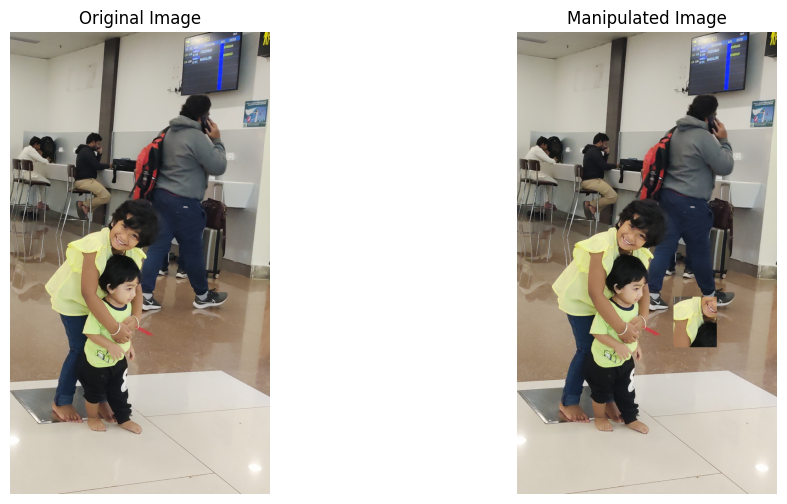

In [9]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use your uploaded original image
original = img.copy()
h, w = original.shape[:2]

# Source region: select a textured area
x1, y1 = 300, 820
x2, y2 = 480, 1030

# Destination: choose a different location
paste_x, paste_y = 650, 1100

patch = original[y1:y2, x1:x2].copy()

ph, pw = patch.shape[:2]

if paste_x + pw > w or paste_y + ph > h:
    raise ValueError("Choose another destination.")

# Create manipulated copy
manipulated = original.copy()

manipulated[
    paste_y:paste_y+ph,
    paste_x:paste_x+pw
] = patch

plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(manipulated)
plt.title("Manipulated Image")
plt.axis("off")

plt.show()


Matching score: 1.0
Detected duplicate: (650, 1100)


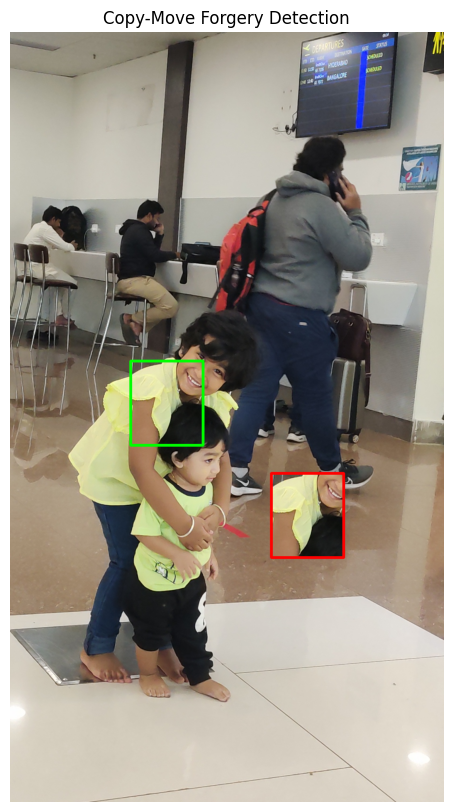

In [10]:

# Convert manipulated image and source patch to grayscale
gray = cv2.cvtColor(manipulated, cv2.COLOR_RGB2GRAY)

template = cv2.cvtColor(patch, cv2.COLOR_RGB2GRAY)

# Template matching
result = cv2.matchTemplate(
    gray,
    template,
    cv2.TM_CCOEFF_NORMED
)

# Exclude the complete original source region
margin = 10

result[
    max(0, y1-margin):min(result.shape[0], y1+margin+1),
    max(0, x1-margin):min(result.shape[1], x1+margin+1)
] = -1

# Find best matching location
_, score, _, location = cv2.minMaxLoc(result)

px, py = location

print("Matching score:", round(score, 4))
print("Detected duplicate:", location)

# Draw bounding boxes
output = manipulated.copy()

# Green = original source
cv2.rectangle(
    output,
    (x1,y1), (x2,y2),
    (0,255,0), 5
)

# Red = detected duplicate
cv2.rectangle(
    output,
    (px,py), (px+pw,py+ph),
    (255,0,0), 5
)

plt.figure(figsize=(9,10))
plt.imshow(output)
plt.title("Copy-Move Forgery Detection")
plt.axis("off")
plt.show()
